# Evaluate
B1 (Qwen's own candidates) vs M (meaning head candidates), at λ 0, 0.25, 0.5, 0.75 and 1, for the 3 rhymed
showcase poets, 4 seeds each = 120 poems.

Measures:
1. rhyme rate: share of the lines that should rhyme that do (score ≥ 0.9, same as everywhere else)
2. fluency: perplexity under a bigger model, Qwen3-1.7B-Base (lowercased, the line-end words are lowercase).
   Lower = reads more naturally
3. copying: share of lines with 5 words in a row that are also somewhere in the training data

Then rhyme rate against perplexity in a plot. If M gets more rhyme for the same perplexity, picking line ends
by meaning is worth it.

Poems are saved in `outputs/sweep/` and skipped if they're already there, so it can carry on after a crash.

In [1]:
%%capture
QUIET = True
%run generate.ipynb

In [2]:
import time
import glob

SWEEP = "../outputs/sweep/"
LAMS = [0.0, 0.25, 0.5, 0.75, 1.0]
SEEDS = range(4)
SYSTEMS = ["B1", "M"]
rhymed_poets = [p for p in showcase.index if showcase.loc[p, "scheme"] != "none"]
print(rhymed_poets)

os.makedirs(SWEEP, exist_ok=True)
t0, made = time.time(), 0
for system in SYSTEMS:
    for poet in rhymed_poets:
        for lam in LAMS:
            for seed in SEEDS:
                path = SWEEP + f"{system}_{poet.replace(' ', '_')}_lam{lam}_seed{seed}.json"
                if os.path.exists(path):
                    continue
                r = generate_poem(poet, lam=lam, seed=seed, system=system)
                with open(path, "w", encoding="utf-8") as f:
                    json.dump(r, f, indent=1, ensure_ascii=False)
                made += 1
print(f"made {made} poems in {(time.time() - t0) / 60:.0f} min")

['Madison Julius Cawein', 'Algernon Charles Swinburne', 'George Gordon Byron']
made 0 poems in 0 min


In [3]:
rows = []
for path in sorted(glob.glob(SWEEP + "*.json")):
    r = json.load(open(path, encoding="utf-8"))
    pairs = [(t["chosen"], t["partner"]) for t in r["lines"] if t["partner"]]
    rows.append({"system": r["system"], "poet": r["poet"], "lam": r["lam"], "seed": r["seed"], "poem": r["poem"],
                 "pairs": len(pairs), "rhymed": sum(rhyme(a, b) >= 0.9 for a, b in pairs)})
res = pd.DataFrame(rows)
print(len(res), "poems")
print(res.groupby(["system", "lam"])[["pairs", "rhymed"]].sum())

120 poems
             pairs  rhymed
system lam                
B1     0.00     60      41
       0.25     60      30
       0.50     60      22
       0.75     60       1
       1.00     60       1
M      0.00     60      51
       0.25     60      32
       0.50     60      17
       0.75     60       2
       1.00     60       1


## Fluency
The generator's model is unloaded first, the 1.7B model needs the space (~3.4 GB).
As a reference: the same score for real poems by the 3 poets (val poems, first 12 lines).

In [4]:
del model, head
torch.cuda.empty_cache()
print(f"{torch.cuda.mem_get_info()[0] / 1e9:.1f} GB GPU memory free")

judge_tok = AutoTokenizer.from_pretrained("../model/Qwen3-1.7B-Base")
judge = AutoModelForCausalLM.from_pretrained("../model/Qwen3-1.7B-Base", dtype=torch.bfloat16).to("cuda").eval()


def perplexity(text):
    ids = torch.tensor([judge_tok(text.lower())["input_ids"]], device="cuda")
    return math.exp(judge(input_ids=ids, labels=ids).loss.item())


res["ppl"] = [perplexity(p) for p in res["poem"]]

val_poems = pd.read_parquet(DATA + "train_test/val.parquet", columns=["author", "text"])
real = []
for poet in rhymed_poets:
    for text in val_poems[val_poems["author"] == poet]["text"].head(8):
        real.append(perplexity("\n".join(poem_lines(text)[:12])))
print(f"real poems by these poets: median perplexity {np.median(real):.1f} ({len(real)} poems)")

5.0 GB GPU memory free


Loading weights: 100%|██████████| 310/310 [00:02<00:00, 111.28it/s]


real poems by these poets: median perplexity 65.6 (24 poems)


## Copying
Every 5 words in a row from the generated lines, then one pass over the training data to see which of them
appear there.

In [5]:
def grams(words, n=5):
    return [tuple(words[i:i + n]) for i in range(len(words) - n + 1)]


wanted = set()
for poem in res["poem"]:
    for line in poem.split("\n"):
        wanted.update(grams(words_of(line)))

found = set()
for text in train["text"]:
    for line in poem_lines(text):
        found.update(g for g in grams(words_of(line)) if g in wanted)


def copied(poem):
    lines = poem.split("\n")
    return np.mean([any(g in found for g in grams(words_of(line))) for line in lines])


res["copied"] = [copied(p) for p in res["poem"]]
print(f"{len(found)} of {len(wanted)} generated 5-grams are in the training data")

30 of 2503 generated 5-grams are in the training data


## Results

In [6]:
table = res.groupby(["system", "lam"]).agg(rhyme_rate=("rhymed", "sum"), pairs=("pairs", "sum"),
                                           ppl=("ppl", "median"), copied=("copied", "mean"))
table["rhyme_rate"] = (table["rhyme_rate"] / table["pairs"]).round(2)
table["ppl"] = table["ppl"].round(1)
table["copied"] = table["copied"].round(3)
print(table)
print()
by_poet = res.groupby(["poet", "system", "lam"])[["rhymed", "pairs"]].sum()
print((by_poet["rhymed"] / by_poet["pairs"]).unstack("lam").round(2))
res.drop(columns="poem").to_csv("../outputs/sweep_scores.csv", index=False)  # every poem's scores

             rhyme_rate  pairs    ppl  copied
system lam                                   
B1     0.00        0.68     60   88.3   0.035
       0.25        0.50     60   73.2   0.028
       0.50        0.37     60   78.2   0.035
       0.75        0.02     60   63.7   0.028
       1.00        0.02     60   63.7   0.028
M      0.00        0.85     60  118.9   0.028
       0.25        0.53     60   87.0   0.042
       0.50        0.28     60   84.2   0.028
       0.75        0.03     60   74.0   0.028
       1.00        0.02     60   68.2   0.028
lam                                0.00  0.25  0.50  0.75  1.00
poet                       system                              
Algernon Charles Swinburne B1      0.67  0.58  0.46  0.00  0.00
                           M       0.88  0.50  0.25  0.00  0.00
George Gordon Byron        B1      0.71  0.54  0.33  0.00  0.00
                           M       0.83  0.58  0.29  0.04  0.00
Madison Julius Cawein      B1      0.67  0.25  0.25  0.08  0.08


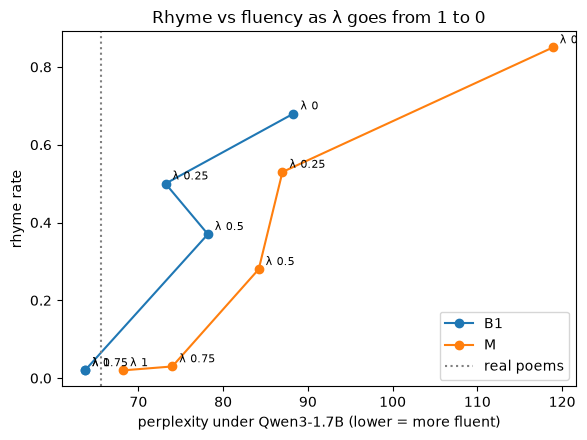

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4.5))
for system, color in [("B1", "tab:blue"), ("M", "tab:orange")]:
    t = table.loc[system]
    ax.plot(t["ppl"], t["rhyme_rate"], "o-", color=color, label=system)
    for lam, row in t.iterrows():
        ax.annotate(f"λ {lam:g}", (row["ppl"], row["rhyme_rate"]), textcoords="offset points", xytext=(5, 3), fontsize=8)
ax.axvline(np.median(real), color="gray", linestyle=":", label="real poems")
ax.set_xlabel("perplexity under Qwen3-1.7B (lower = more fluent)")
ax.set_ylabel("rhyme rate")
ax.set_title("Rhyme vs fluency as λ goes from 1 to 0")
ax.legend()
plt.tight_layout()
plt.savefig("../outputs/lambda_curve.png", dpi=150)
plt.show()

## Poems to choose from
For the presentation: 5 new poems (seeds 10-14) per showcase poet, with both systems at every λ (Longfellow
only λ 1) = 160 poems. Each one is saved in `outputs/final/`, and all of them in one file to read through,
`outputs/final_poems.txt`. We pick the 3 to present by hand from these and write down how many we looked at.

In [8]:
del judge
torch.cuda.empty_cache()
%run generate.ipynb

FINAL = "../outputs/final/"
os.makedirs(FINAL, exist_ok=True)
t0 = time.time()
for system in SYSTEMS:
    for poet in showcase.index:
        for lam in (LAMS if showcase.loc[poet, "scheme"] != "none" else [1.0]):
            for seed in range(10, 15):
                path = FINAL + f"{system}_{poet.replace(' ', '_')}_lam{lam}_seed{seed}.json"
                if os.path.exists(path):
                    continue
                r = generate_poem(poet, lam=lam, seed=seed, system=system)
                with open(path, "w", encoding="utf-8") as f:
                    json.dump(r, f, indent=1, ensure_ascii=False)
print(f"took {(time.time() - t0) / 60:.0f} min")

final = [json.load(open(p, encoding="utf-8")) for p in sorted(glob.glob(FINAL + "*.json"))]
with open("../outputs/final_poems.json", "w", encoding="utf-8") as f:
    json.dump(final, f, indent=1, ensure_ascii=False)
with open("../outputs/final_poems.txt", "w", encoding="utf-8") as f:
    for r in final:
        pairs = [(t["chosen"], t["partner"]) for t in r["lines"] if t["partner"]]
        rhymed = sum(rhyme(a, b) >= 0.9 for a, b in pairs)
        f.write(f"===== {r['poet']} | {r['system']} | λ {r['lam']} | seed {r['seed']} | {rhymed}/{len(pairs)} rhyme pairs =====\n")
        f.write(r["poem"] + "\n\n")
print("saved", len(final), "poems")

                           scheme  syl_min  syl_max  lam
poet                                                    
Henry Wadsworth Longfellow   none        8       10  1.0
Madison Julius Cawein        ABCB        7       10  0.5
Algernon Charles Swinburne   AABB        8       11  0.5
George Gordon Byron          ABAB       10       11  0.5


Loading weights: 100%|██████████| 310/310 [00:00<00:00, 457.60it/s]


model: lora
18395 line-end words, 16708 of them as single tokens (B1)
meaning head: loaded
AABB partners: {1: 0, 3: 2} opens: {0, 2}
ABAB partners: {2: 0, 3: 1} opens: {0, 1}
ABCB partners: {3: 1} opens: {1}
took 28 min
saved 160 poems
